
# Лабораторная работа №2. Классификация: Titanic

**Цель:** пройти полный цикл решения задачи бинарной классификации — исследовать данные пассажиров «Титаника», подготовить признаки, построить baseline, обучить и сравнить несколько алгоритмов машинного обучения, проанализировать метрики, важность признаков и ошибки моделей.

**Источник:** [Titanic Dataset — Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset).


In [3]:
import pandas as pd
from pathlib import Path

# Загрузка данных
data_path = Path("lab02/data/Titanic-Dataset.csv")

if not data_path.exists():
    data_path = Path("data/Titanic-Dataset.csv")

df = pd.read_csv(data_path)

from IPython.display import display

print("Размер датасета:", df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые пять пассажиров:")
display(df.head())

Размер датасета: (891, 12)

Названия столбцов:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Первые пять пассажиров:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Типы данных, пропуски и дубликаты

Проверим типы столбцов, количество отсутствующих значений и наличие повторяющихся записей.

In [4]:
# Типы признаков
print("Типы данных:")
print(df.dtypes.to_string())

# Пропущенные значения
missing = pd.DataFrame({
    "Количество": df.isna().sum(),
    "Процент": df.isna().mean() * 100
})

print("\nПропущенные значения:")
print(missing[missing["Количество"] > 0].round(2).to_string())

# Проверяем дубликаты
print("\nПолные дубликаты:", df.duplicated().sum())

print(
    "Повторяющиеся PassengerId:",
    df["PassengerId"].duplicated().sum()
)

Типы данных:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Пропущенные значения:
          Количество  Процент
Age              177    19.87
Cabin            687    77.10
Embarked           2     0.22

Полные дубликаты: 0
Повторяющиеся PassengerId: 0



**Вывод:** в датасете 891 пассажир, полных дубликатов и повторяющихся PassengerId нет. Пропуски обнаружены в Age (19.87%), Cabin (77.10%) и Embarked (0.22%).

Для Age будем использовать медиану, для Embarked — наиболее частое значение. Cabin пока исключим из модели из-за большого количества пропусков.



## 3. Разделение данных

Разделим датасет на обучающую и тестовую выборки в соотношении 80/20. Используем стратификацию по Survived, чтобы сохранить распределение классов, и зафиксируем random_state для воспроизводимости.


In [7]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Survived"]
)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("\nДоля выживших:")
print(f"Train: {train_df['Survived'].mean():.3f}")
print(f"Test:  {test_df['Survived'].mean():.3f}")

Train: (712, 12)
Test: (179, 12)

Доля выживших:
Train: 0.383
Test:  0.385



### Валидационная выборка

Дополнительно выделим 20% обучающей выборки для валидации. На ней будем сравнивать модели и подбирать параметры, не используя тестовые данные.


In [8]:
fit_df, val_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42,
    stratify=train_df["Survived"]
)

print("Fit:", fit_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nДоля выживших:")
print(f"Fit: {fit_df['Survived'].mean():.3f}")
print(f"Validation: {val_df['Survived'].mean():.3f}")
print(f"Test: {test_df['Survived'].mean():.3f}")

Fit: (569, 12)
Validation: (143, 12)
Test: (179, 12)

Доля выживших:
Fit: 0.383
Validation: 0.385
Test: 0.385



## 4. Предобработка признаков

Обработаем пропуски, закодируем категориальные признаки и масштабируем числовые. Все параметры преобразований будем вычислять только на обучающих данных, чтобы избежать утечки информации.



In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Pclass", "Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

features = numeric_features + categorical_features

X_fit = fit_df[features]
X_val = val_df[features]

y_fit = fit_df["Survived"]
y_val = val_df["Survived"]

X_fit_processed = preprocessor.fit_transform(X_fit)
X_val_processed = preprocessor.transform(X_val)

print("Fit:", X_fit_processed.shape)
print("Validation:", X_val_processed.shape)

print("\nНовые признаки:")
print(preprocessor.get_feature_names_out())

Fit: (569, 12)
Validation: (143, 12)

Новые признаки:
['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'cat__Pclass_1'
 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female' 'cat__Sex_male'
 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S']



## 5. Baseline-модель

В качестве базовой модели используем DummyClassifier, который всегда предсказывает наиболее частый класс. Оценим Accuracy, Precision, Recall, F1-score и построим матрицу ошибок.


Accuracy: 0.615
Precision: 0.0
Recall: 0.0
F1: 0.0


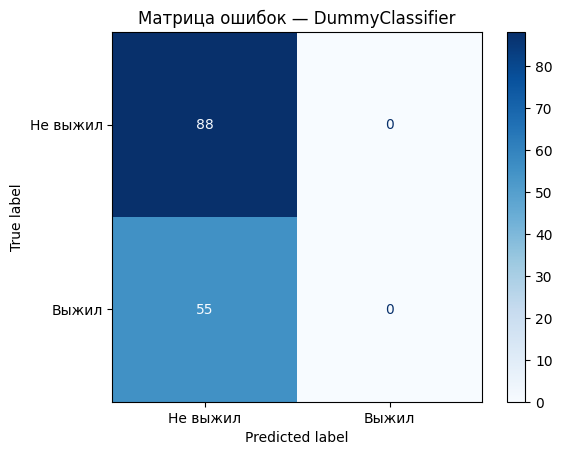

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_fit_processed, y_fit)

y_pred_baseline = baseline.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_baseline), 3))
print("Precision:", round(precision_score(y_val, y_pred_baseline, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, y_pred_baseline, zero_division=0), 3))
print("F1:", round(f1_score(y_val, y_pred_baseline, zero_division=0), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_baseline,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — DummyClassifier")
plt.show()


**Вывод:** DummyClassifier показал Accuracy = 0.615, однако Precision, Recall и F1 равны нулю. Модель всегда предсказывает наиболее частый класс (0), поэтому правильно определила 88 погибших, но не распознала ни одного из 55 выживших.

Таким образом, Accuracy недостаточно для оценки качества классификации. Далее будем сравнивать модели преимущественно по F1-score.



## 6. Decision Tree

Обучим дерево решений и сравним качество на обучающей и валидационной выборках. Проверим, не возникает ли переобучения.


F1 на Fit: 0.974
F1 на Validation: 0.719

Метрики на Validation:
Accuracy: 0.776
Precision: 0.695
Recall: 0.745
F1: 0.719


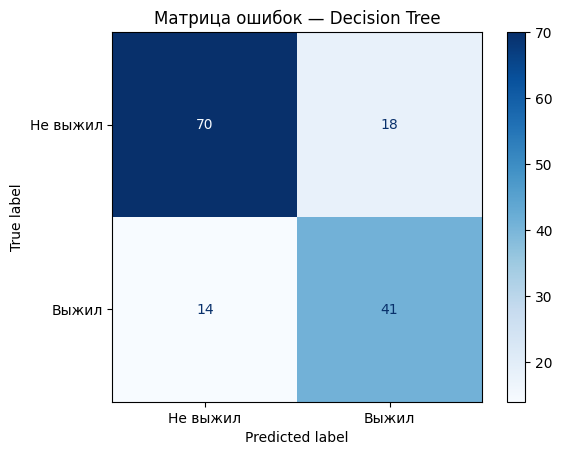

In [11]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)

tree.fit(X_fit_processed, y_fit)

y_pred_fit = tree.predict(X_fit_processed)
y_pred_val = tree.predict(X_val_processed)

print("F1 на Fit:", round(f1_score(y_fit, y_pred_fit), 3))
print("F1 на Validation:", round(f1_score(y_val, y_pred_val), 3))

print("\nМетрики на Validation:")
print("Accuracy:", round(accuracy_score(y_val, y_pred_val), 3))
print("Precision:", round(precision_score(y_val, y_pred_val), 3))
print("Recall:", round(recall_score(y_val, y_pred_val), 3))
print("F1:", round(f1_score(y_val, y_pred_val), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_val,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Decision Tree")
plt.show()


### Влияние глубины дерева

Проверим, как максимальная глубина дерева влияет на качество классификации. Сравним F1-score на обучающей и валидационной выборках, чтобы найти баланс между недообучением и переобучением.


,max_depth,F1 Fit,F1 Validation
0,1,0.719,0.698
1,2,0.744,0.739
2,3,0.739,0.771
3,4,0.752,0.763
4,5,0.805,0.774
5,6,0.823,0.755
6,7,0.863,0.745
7,8,0.892,0.759
8,9,0.920,0.750
9,10,0.937,0.739


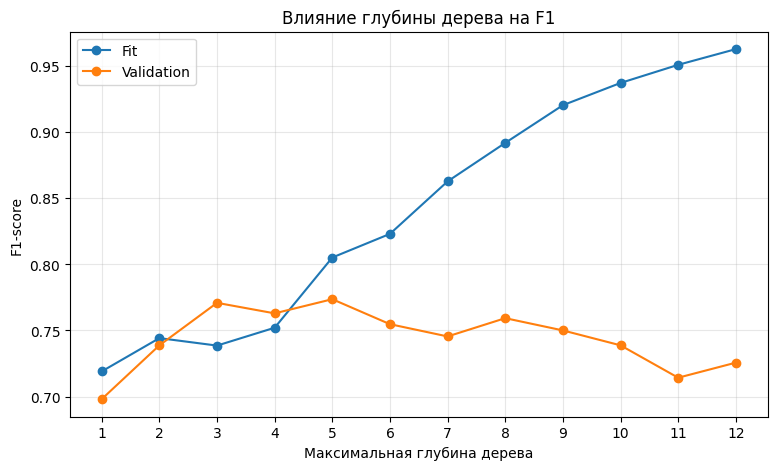

In [12]:
depths = range(1, 13)

fit_scores = []
val_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_fit_processed, y_fit)

    fit_scores.append(
        f1_score(y_fit, model.predict(X_fit_processed))
    )

    val_scores.append(
        f1_score(y_val, model.predict(X_val_processed))
    )

results = pd.DataFrame({
    "max_depth": depths,
    "F1 Fit": fit_scores,
    "F1 Validation": val_scores
})

display(results.round(3))

plt.figure(figsize=(9, 5))
plt.plot(depths, fit_scores, marker="o", label="Fit")
plt.plot(depths, val_scores, marker="o", label="Validation")

plt.xlabel("Максимальная глубина дерева")
plt.ylabel("F1-score")
plt.title("Влияние глубины дерева на F1")
plt.xticks(list(depths))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Вывод:** наилучший F1 на валидационной выборке (0.774) получен при max_depth = 5. При дальнейшем увеличении глубины качество на обучающей выборке продолжает расти, однако на валидационной снижается, что указывает на переобучение.

Для дальнейшего сравнения моделей выберем дерево с max_depth = 5.


Accuracy: 0.832
Precision: 0.804
Recall: 0.745
F1: 0.774


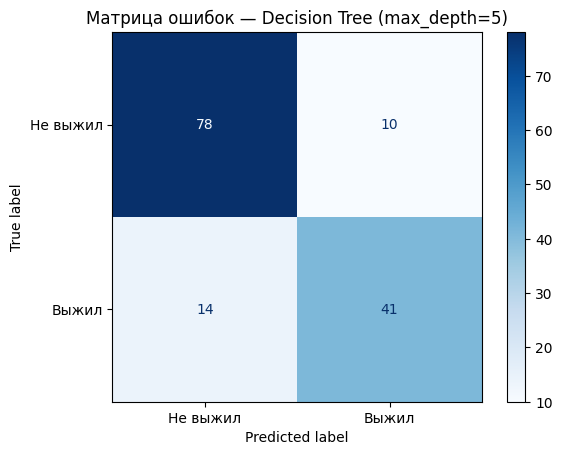

In [13]:
best_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

best_tree.fit(X_fit_processed, y_fit)

y_pred_tree = best_tree.predict(X_val_processed)

print("Accuracy:", round(accuracy_score(y_val, y_pred_tree), 3))
print("Precision:", round(precision_score(y_val, y_pred_tree), 3))
print("Recall:", round(recall_score(y_val, y_pred_tree), 3))
print("F1:", round(f1_score(y_val, y_pred_tree), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_tree,
    labels=[0, 1],
    display_labels=["Не выжил", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок — Decision Tree (max_depth=5)")
plt.show()